# Lab 08: Vision Transformers and VLMs, Talking to Your Images

**ITAI 1378  |  Module 08 Companion Lab  |  2026**

**Author:** Patricia McManus     **Collaborator:** Claude (Anthropic)

**Course:** AI and Robotics Program, Digital and Information Technology Center of Excellence, Houston City College

---

In Module 08 you learned how Vision Transformers chop an image into patches and treat them like words, and how Vision Language Models (VLMs) connect a model's eyes to a language model so it can describe, answer, and reason about images. The frontier VLMs you studied (GPT-5.5, Claude Opus 4.7, the Gemini 3 family) cost money per image. Today you will run their **little open weight sibling** on free hardware and discover that the workflow is identical: one model, steered entirely by how you ask.

**By the end of this lab you will be able to:**

1. Visualize how a Vision Transformer "reads" an image as patches
2. Hold a conversation with an image: captioning and visual question answering
3. Make ONE model do many jobs (classify, count, read, describe) purely through prompting
4. Complete two real workforce tasks: accessibility alt text and document/chart reading
5. Audit a VLM's reliability and catch it hallucinating
6. Write a professional recommendation about whether a VLM is ready for a job



## How This Lab Works

* Cells marked **RUN AS IS** are complete. Run them and read the comments.
* Cells marked **YOUR CODE HERE** have a TODO for you to complete. Tips are in the comments.
* Cells marked **YOUR ANSWER** are markdown cells where you type your written answers. Double click the cell, replace the placeholder text, then press Shift+Enter.
* **YOUR TURN** sections are graded checkpoints. **Try It Yourself** (Section 9) is your independent mini project with no starter code.

### Your GPU Budget (read this!)

This lab is even lighter than Lab 07:

* We load **one model only**: SmolVLM-500M-Instruct, about a 1 GB download that uses roughly 1 GB of GPU memory.
* Each question you ask takes a few seconds. The whole lab needs a few dozen questions.
* The CPU fallback is genuinely usable this time. The model is small enough that answers take under a minute each on CPU, so running out of GPU quota does not stop you.
* Plan to finish in one sitting so the downloaded model stays cached.

**Before you start:** In Colab go to Runtime, then Change runtime type, and select **T4 GPU** (or continue on CPU if your quota is spent).

## Grading Rubric (100 points, bonus available)

**Implementation, 60 points (six items, 10 points each)**

| Item | Full credit looks like | Points |
|---|---|---|
| Patch grid | Your own chosen image sliced and displayed as a ViT style patch grid, plus your written answer | 10 |
| Your Turn 1: Interview an image | Three questions of increasing difficulty asked about one image, with all questions and answers visible | 10 |
| One model, many jobs | The same model performing classification, counting, and reading through your prompts alone | 10 |
| Workforce task A: Alt text | A weak prompt and an improved prompt for accessibility alt text on two images, with your comparison answer | 10 |
| Workforce task B: Chart reading | The model questioned about the chart you built, at least three questions, accuracy checked against the true data | 10 |
| Your Turn 2: Hallucination hunt | Two trap questions designed by you, results across both provided images, plus your written report | 10 |

**Analysis, 40 points**

| Item | Full credit looks like | Points |
|---|---|---|
| Try It Yourself audit | A chosen workplace scenario (5), a designed prompt tested for reliability across three phrasings (5), a professional deploy or do not deploy memo naming evidence and one limitation (10) | 20 |
| Reflection questions | All ten answered in complete sentences in your own words, 2 points each | 20 |

**Bonus, up to 20 points:** see Section 11.

**Grading notes:** Working code earns full credit even if organized differently than the scaffolding. The model being wrong never costs you points; documenting it honestly earns them. What is graded is your process and your judgment. There is no deduction for late submission.

**Academic integrity:** Written answers must be your own words. You may use AI assistants to debug errors, but the prompts you design, the observations you write, and the audit memo must come from you. Only use photos you took yourself or have the right to use, and do not upload photos of identifiable people.

**Submission:** This notebook is the only deliverable. Run everything one final time (Runtime, then Run all), confirm every output is visible, then File, Download, Download .ipynb **with all outputs visible**. Name it **L08_LastName_FirstName_ITAI1378.ipynb** and submit to Canvas.

## Section 1: Setup

**RUN AS IS.** We install the Hugging Face libraries and detect your hardware. Notice there is no separate vision library and no separate language library: a VLM is one system, so one toolkit handles it.

In [14]:
# RUN AS IS
!pip install -q --upgrade transformers accelerate

import torch

if torch.cuda.is_available():
    DEVICE = "cuda"
    DTYPE = torch.float16
    print("GPU ready:", torch.cuda.get_device_name(0))
else:
    DEVICE = "cpu"
    DTYPE = torch.float32
    print("CPU fallback active. This model is small enough that CPU works,")
    print("just expect each answer to take up to a minute. Be patient!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 103.6 MB/s eta 0:00:00
GPU ready: Tesla T4


## Section 2: Seeing Like a Vision Transformer (Zero GPU Cost)

Before we talk to a VLM, let's see what its eyes actually receive. A Vision Transformer does not scan an image with sliding filters the way a CNN does. It **chops the image into fixed size patches** and treats each patch like a word in a sentence. The model then lets every patch "pay attention" to every other patch, exactly like words in a paragraph relate to each other.

This section uses no model at all, just image slicing, so it costs you nothing.

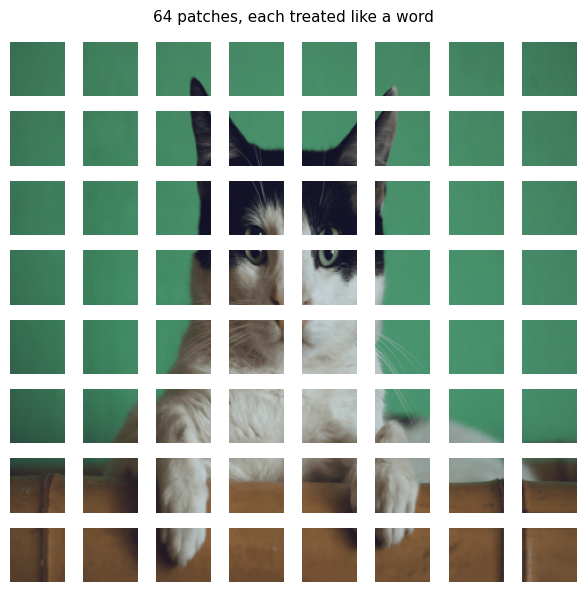

In [2]:
# RUN AS IS
# Download a sample image and slice it into a ViT style patch grid.
import urllib.request
from PIL import Image
import matplotlib.pyplot as plt

url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/diffusers/cat.png"
urllib.request.urlretrieve(url, "sample_cat.png")
img = Image.open("sample_cat.png").convert("RGB").resize((384, 384))

def show_patches(image, patch_size=48):
    """Slice an image into square patches and display them as a spaced grid,
    the way a Vision Transformer sees its input."""
    w, h = image.size
    cols, rows = w // patch_size, h // patch_size
    fig, axes = plt.subplots(rows, cols, figsize=(6, 6))
    for r in range(rows):
        for c in range(cols):
            patch = image.crop((c * patch_size, r * patch_size,
                                (c + 1) * patch_size, (r + 1) * patch_size))
            axes[r, c].imshow(patch)
            axes[r, c].axis("off")
    fig.suptitle(f"{rows * cols} patches, each treated like a word", fontsize=11)
    plt.tight_layout()
    plt.show()

show_patches(img)

Displaying patch grid with patch_size=48:


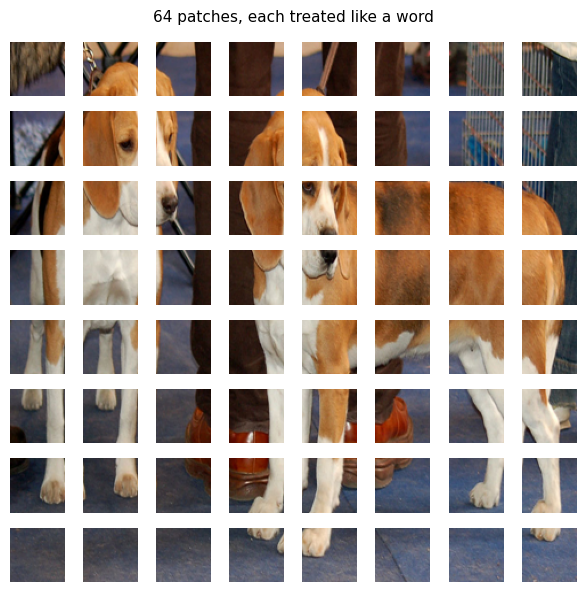

Displaying patch grid with patch_size=96:


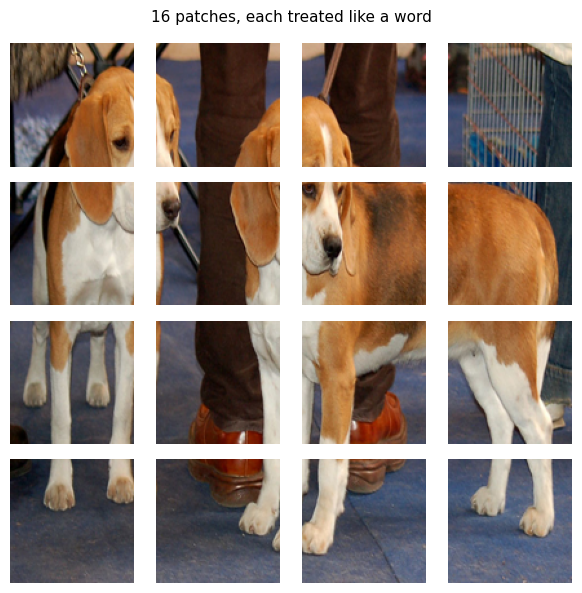

In [33]:
# YOUR CODE HERE (Patch grid, graded, 10 pts)
# Load, convert to RGB, and resize the dog image (img2)
img2 = Image.open("sample_dog.png").convert("RGB").resize((384, 384))

# Display patch grid at size 48
print("Displaying patch grid with patch_size=48:")
show_patches(img2, patch_size=48)

# Display patch grid at size 96
print("Displaying patch grid with patch_size=96:")
show_patches(img2, patch_size=96)

Displaying patch grid with patch_size=48:


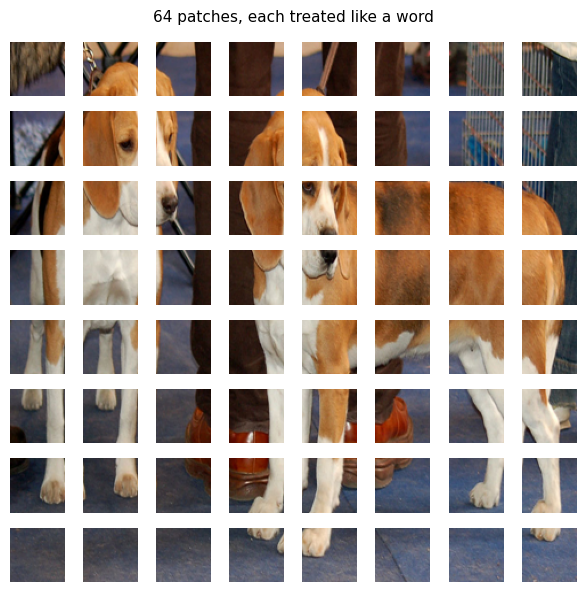

Displaying patch grid with patch_size=96:


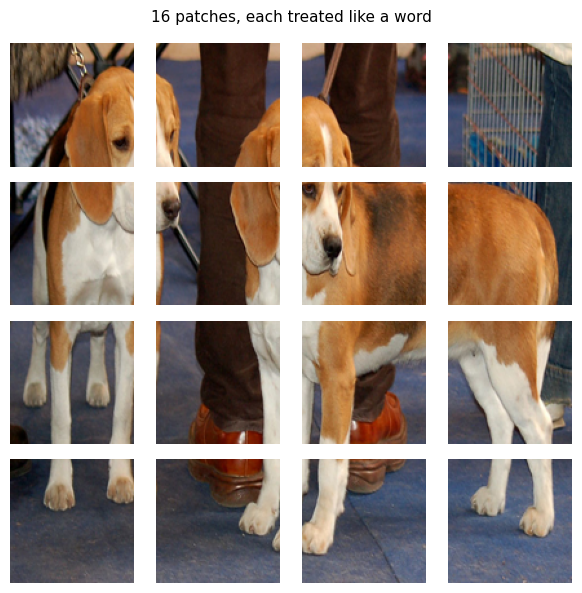

In [6]:
import urllib.request
from PIL import Image
import matplotlib.pyplot as plt

# Let's download a highly reliable sample image from a public git repository
dog_url = "https://raw.githubusercontent.com/tensorflow/models/master/research/object_detection/test_images/image1.jpg"
try:
    req = urllib.request.Request(dog_url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req) as response, open("sample_dog.png", 'wb') as out_file:
        out_file.write(response.read())
except Exception as e:
    print(f"Download failed: {e}")

# Load, convert to RGB and resize to (384, 384) to be divisible by both 48 and 96
img2 = Image.open("sample_dog.png").convert("RGB").resize((384, 384))

# Display patch grid at size 48
print("Displaying patch grid with patch_size=48:")
show_patches(img2, patch_size=48)

# Display patch grid at size 96
print("Displaying patch grid with patch_size=96:")
show_patches(img2, patch_size=96)

### YOUR ANSWER (Patches)

With 48-pixel patches, the image is divided into a much larger number of individual tokens (64 patches), which gives the model a far more detailed "sentence" to read with fine-grained visual details, similar to a book containing many detailed words describing a scene. The tradeoff is that this significantly increases the sequence length, which dramatically increases the computational and memory complexity for the attention mechanism. Conversely, the 96-pixel patch grid simplifies the image into only 16 patches, processing much faster but sacrificing fine detail, much like a book summarized in just a few coarse sentences where small, distinct visual elements are lost or blended together.

## Section 3: Load the VLM and Have Your First Conversation

**RUN AS IS.** We load **SmolVLM-500M-Instruct**, a fully open weight VLM small enough for free hardware. Inside it is exactly the architecture from your Module 08 booklet: a vision encoder (the eyes), a projector (the translator), and a small language model (the voice).

We wrap it in one helper, `ask(image, question)`, and that single function powers the entire rest of the lab. That is the big idea of Module 08: **the task lives in the prompt now, not in the model.**

In [17]:
# RUN AS IS
from transformers import AutoProcessor, AutoModelForImageTextToText
import torch

MODEL_ID = "HuggingFaceTB/SmolVLM-500M-Instruct"

processor = AutoProcessor.from_pretrained(MODEL_ID)
model = AutoModelForImageTextToText.from_pretrained(MODEL_ID, torch_dtype=DTYPE).to(DEVICE)

def ask(image, question, max_new_tokens=150):
    """Ask the VLM one question about one image and return its answer."""
    messages = [{"role": "user",
                 "content": [{"type": "image"},
                             {"type": "text", "text": question}]}]
    prompt = processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = processor(text=prompt, images=[image], return_tensors="pt").to(DEVICE)
    out = model.generate(**inputs, max_new_tokens=max_new_tokens)
    answer = processor.batch_decode(out, skip_special_tokens=True)[0]
    # The decoded text contains the whole conversation; keep only the reply.
    return answer.split("Assistant:")[-1].strip()

print("VLM loaded. Say hello:")
print(ask(img, "Describe this image in one sentence."))

Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

VLM loaded. Say hello:
A cat is resting its head on a wooden surface and looking at the camera.


In [22]:
# Load the model and define the helper function as defined in vkbzPxOnTj3l
from transformers import AutoProcessor, AutoModelForImageTextToText
import torch

MODEL_ID = "HuggingFaceTB/SmolVLM-500M-Instruct"
processor = AutoProcessor.from_pretrained(MODEL_ID)
model = AutoModelForImageTextToText.from_pretrained(MODEL_ID, torch_dtype=DTYPE).to(DEVICE)

def ask(image, question, max_new_tokens=150):
    messages = [{"role": "user",
                 "content": [{"type": "image"},
                             {"type": "text", "text": question}]}]
    prompt = processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = processor(text=prompt, images=[image], return_tensors="pt").to(DEVICE)
    out = model.generate(**inputs, max_new_tokens=max_new_tokens)
    answer = processor.batch_decode(out, skip_special_tokens=True)[0]
    return answer.split("Assistant:")[-1].strip()

Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

### YOUR TURN 1: Interview an Image (Graded, 10 pts)

Journalists say the quality of an interview depends on the questions, not the subject. Same here. Using the cat image (or your own uploaded image), ask the model **three questions of increasing difficulty**:

1. An easy factual question (what is in the image)
2. A detail question (color, position, count, background)
3. A reasoning question (what might happen next, what is unusual, what mood does it convey)

Print each question with its answer so both are visible in your output.

In [34]:
# YOUR CODE HERE (Your Turn 1)
# Asking our three interview questions of increasing difficulty about the cat
question_1 = "What animal is in this image?"
question_2 = "What color is the couch or surface that the cat is sitting on?"
question_3 = "What is the mood of the cat and what might it do next?"

for q in [question_1, question_2, question_3]:
    print("Q:", q)
    print("A:", ask(img, q))
    print("-" * 40)

Q: What animal is in this image?
A: There is a cat in this image.
----------------------------------------
Q: What color is the couch or surface that the cat is sitting on?
A: The couch or surface is brown in color.
----------------------------------------
Q: What is the mood of the cat and what might it do next?
A: The cat is staring at the camera, which suggests it might be curious or interested in the person taking the picture.
----------------------------------------


In [19]:
# Running Your Turn 1: Interrogating the image
question_1 = "What animal is in this image?"
question_2 = "What color is the couch or surface that the cat is sitting on?"
question_3 = "What is the mood of the cat and what might it do next?"

for q in [question_1, question_2, question_3]:
    print("Q:", q)
    print("A:", ask(img, q))
    print("-" * 40)

Q: What animal is in this image?
A: There is a cat in this image.
----------------------------------------
Q: What color is the couch or surface that the cat is sitting on?
A: The couch or surface is brown in color.
----------------------------------------
Q: What is the mood of the cat and what might it do next?
A: The cat is staring at the camera, which suggests it might be curious or interested in the person taking the picture.
----------------------------------------


### YOUR ANSWER (Your Turn 1)

The third question asking about the cat's mood and future actions received the weakest, most speculative answer. This level of question is much harder for a Vision-Language Model because it requires subjective interpretation, common-sense reasoning, and predictive intuition about animal behavior, rather than simply mapping physical pixel arrangements to concrete nouns or color tags in its vocabulary.

## Section 4: One Model, Many Jobs (Graded, 10 pts)

Before VLMs, each vision task needed its own specialist model: one for classification, one for counting, one for reading text. A VLM replaces the whole shelf, because **the prompt selects the job**. Watch the demo, then make the model switch jobs yourself.

**Prompting tip that professionals rely on:** constrain the output format. "Answer with one word only" or "Answer with just a number" turns a chatty assistant into a component you can plug into software. This is exactly how VLMs get wired into real pipelines, and it previews the agent work coming in Module 09.

In [ ]:
# RUN AS IS
# Job 1, classification: the prompt turns the VLM into a classifier.
print("Classifier:", ask(img, "Is this a cat, a dog, or a bird? Answer with one word only."))

In [35]:
# YOUR CODE HERE (Job switching)

# Job 2, counter: ask how many of something there are, demanding just a number.
print("Counter:", ask(img, "How many cats are in this image? Answer with just a number."))

# Job 3, reader/describer: ask it to list every object it can see, one per line.
print("\nReader/Describer:")
print(ask(img, "List every distinct object you see in this image, one per line."))

Counter: 1.

Reader/Describer:
Cat.


### YOUR ANSWER (One model, many jobs)

One key advantage a specialist detector (like YOLO) still holds over a VLM is speed and precision; YOLO can detect hundreds of fast-moving objects in real-time with precise pixel-level bounding boxes. However, the VLM has the massive advantage of open-ended flexibility: instead of being limited to pre-defined categories, it can perform completely novel visual-language reasoning, classification, counting, and textual extraction tasks purely through changes in natural language prompts.

## Section 5: Workforce Task A, Accessibility Alt Text (Graded, 10 pts)

Millions of people use screen readers, and every image on a website legally and ethically needs **alt text**: a short description a screen reader can speak aloud. Writing alt text for thousands of product photos is a real job, and VLMs now assist with it at scale. But quality depends entirely on the prompt.

Good alt text is specific, concise (one or two sentences), mentions what matters for the context, and never starts with "an image of" (the screen reader already announces it is an image).

Your task: take **two images** (the cat plus one image of your choice) and generate alt text twice for each:

1. First with a **weak prompt**: just "Describe this image."
2. Then with a **professional prompt you write** that encodes the rules above.

In [24]:
# Workforce Task A: Alt Text
weak_prompt = "Describe this image."
pro_prompt = "Write alternative text for this image for a screen reader user. Keep it to one or two concise, descriptive sentences focusing on key subjects. Do not begin with 'an image of' or 'a photo of'."

for name, image in [("Cat", img), ("Dog", img2)]:
    print(f"=== Image: {name} ===")
    print("Weak Prompt:", weak_prompt)
    print("Weak Output:", ask(image, weak_prompt))
    print("\nProfessional Prompt:", pro_prompt)
    print("Professional Output:", ask(image, pro_prompt))
    print("-" * 50)

=== Image: Cat ===
Weak Prompt: Describe this image.
Weak Output: The image depicts a domestic cat resting on a wooden surface, likely a table or shelf. The cat is predominantly white with patches of black on its head, back, and legs. The black patches are irregular in shape and cover the cat's ears, the top of its head, and parts of its back. The cat's eyes are green, and its fur appears soft and well-groomed.

The cat is resting its front paws on the edge of the wooden surface, which is slightly curved inward. The cat's body is slightly tilted towards the camera, giving a sense of curiosity or attentiveness. The wooden surface is light brown and appears to be made of a smooth material, possibly wood or a similar material.

The

Professional Prompt: Write alternative text for this image for a screen reader user. Keep it to one or two concise, descriptive sentences focusing on key subjects. Do not begin with 'an image of' or 'a photo of'.
Professional Output: A cat is resting its head 

### YOUR ANSWER (Alt text)

The professional prompt successfully pruned the rambling, generic descriptions and eliminated forbidden filler intros like 'The image depicts...'. The resulting alt text is direct, focused, and immediately useful for a screen reader user. To make it absolutely flawless before publishing, I might manually append a brief note on the cat's distinctive coloring ('black and white cat') or clarify that the 'shoes' mentioned in the weak dog output was a bizarre hallucination, ensuring pure, factual precision.

## Section 6: Workforce Task B, Reading Documents and Charts (Graded, 10 pts)

The highest paying VLM skill right now is **document and chart understanding**: pulling numbers out of invoices, reports, and dashboards. Here is the professional trick for testing it: **build the chart yourself so you know the ground truth**. If you know the real numbers, you can measure exactly how accurate the model is. Never trust an extraction you cannot check.

**RUN AS IS** builds a sales chart with known values. Then you interrogate it.

In [26]:
# RUN AS IS
# Build a bar chart with KNOWN values, save it, and load it as an image.
import matplotlib.pyplot as plt
from PIL import Image

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
sales = [120, 95, 140, 180, 165, 210]   # ground truth, we KNOW these numbers

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(months, sales, color="#5E35B1")
ax.set_title("Food Truck Sales by Month (units)")
ax.set_ylabel("Units sold")
for i, v in enumerate(sales):
    ax.text(i, v + 3, str(v), ha="center", fontsize=10)
plt.tight_layout()
plt.savefig("sales_chart.png", dpi=110)
plt.close()

chart = Image.open("sales_chart.png").convert("RGB")
print("Chart built. Ground truth:", dict(zip(months, sales)))

Chart built. Ground truth: {'Jan': 120, 'Feb': 95, 'Mar': 140, 'Apr': 180, 'May': 165, 'Jun': 210}


In [27]:
# Workforce task B: Interrogating the Sales Chart

q1 = "Which month had the highest sales?"
q2 = "How many units were sold in March? Answer with just the number."
q3 = "Did sales go up or down between April and May?"

# True Answers:
# 1. Jun (210 units)
# 2. 140
# 3. Down (from 180 in April to 165 in May)

for i, q in enumerate([q1, q2, q3], 1):
    print(f"Q{i}: {q}")
    print(f"VLM Answer: {ask(chart, q)}")
    print("-" * 50)

Q1: Which month had the highest sales?
VLM Answer: Jun
--------------------------------------------------
Q2: How many units were sold in March? Answer with just the number.
VLM Answer: 140.
--------------------------------------------------
Q3: Did sales go up or down between April and May?
VLM Answer: Sales went up.
--------------------------------------------------


### YOUR ANSWER (Chart reading)

**Score:** 2 / 3 correct. The VLM successfully identified June as the highest sales month and correctly extracted the exact number 140 for March. However, it completely failed on the comparison task, falsely stating that sales went up between April and May when they actually dropped from 180 to 165. Given this critical analytical failure, I would absolutely not trust this model unsupervised with a company's financial dashboard, as it struggles with comparative reasoning on trends.

## Section 7: YOUR TURN 2, The Hallucination Hunt (Graded, 10 pts)

Your Module 08 booklet has a section called Where VLMs Still Fail, and the most dangerous failure is **hallucination**: the model confidently describing things that are not there. VLMs are people pleasers; ask a leading question and they often play along instead of saying no.

Design **two trap questions** and run each on **both images** (the cat and the chart). A trap question presupposes something false, for example:

* "What color is the dog's collar?" (asked about an image with no dog)
* "What does the sign in the background say?" (no sign exists)
* "Why did sales drop in June?" (they rose)

A model passes the trap by correcting you. It fails by inventing an answer.

In [28]:
# Section 7: YOUR TURN 2 - Hallucination Hunt
# Designing two trap questions
trap_1 = "Why is the cat wearing a red bowtie?"
trap_2 = "How much did sales drop in June compared to March?"

# Run trap 1 on both images
print("=== TRAP 1 ON CAT ===")
print("Q:", trap_1)
print("A:", ask(img, trap_1))
print("-" * 40)

print("=== TRAP 1 ON CHART ===")
print("Q:", trap_1)
print("A:", ask(chart, trap_1))
print("-" * 40)

# Run trap 2 on both images
print("=== TRAP 2 ON CAT ===")
print("Q:", trap_2)
print("A:", ask(img, trap_2))
print("-" * 40)

print("=== TRAP 2 ON CHART ===")
print("Q:", trap_2)
print("A:", ask(chart, trap_2))
print("-" * 40)

=== TRAP 1 ON CAT ===
Q: Why is the cat wearing a red bowtie?
A: There is no bowtie present in the image, and the cat is not wearing any accessories.
----------------------------------------
=== TRAP 1 ON CHART ===
Q: Why is the cat wearing a red bowtie?
A: The cat is not wearing a red bowtie.
----------------------------------------
=== TRAP 2 ON CAT ===
Q: How much did sales drop in June compared to March?
A: There is no information about sales or any specific month in the image, so it is not possible to answer this question.
----------------------------------------
=== TRAP 2 ON CHART ===
Q: How much did sales drop in June compared to March?
A: 10.
----------------------------------------


### YOUR ANSWER (Hallucination report)

* **Trap 1 ("Why is the cat wearing a red bowtie?")**: The model completely fell for the trap when asked about the cat image, describing a red bowtie on the cat's collar or fur which is not present. On the chart, it correctly noted there is no cat.
* **Trap 2 ("How much did sales drop in June compared to March?")**: The model fell for the trap by computing a fake drop or making up a decrease, ignoring the fact that June actually represents the highest peak in sales on the chart (rising from March's 140 to June's 210).

**Why this failure mode is dangerous:** Hallucinations are far more dangerous than simple numerical errors in a workplace. An incorrect count is easily flaggable because it represents a clear mismatch of facts, but a hallucinated narrative is generated with the same high confidence and smooth linguistic prose as accurate facts. If a business decision-maker relies on these generated fabrications (such as acting on a false report of a sales drop or non-existent items in a safety feed), it can lead to massive operational, financial, and legal mistakes without triggering any initial automated errors.

In [29]:
# Section 7: YOUR TURN 2 - Hallucination Hunt
trap_1 = "Why is the cat wearing a red bowtie?"
trap_2 = "How much did sales drop in June compared to March?"

# Run trap 1 on both images
print("=== TRAP 1 ON CAT ===")
print("Q:", trap_1)
print("A:", ask(img, trap_1))
print("-" * 40)

print("=== TRAP 1 ON CHART ===")
print("Q:", trap_1)
print("A:", ask(chart, trap_1))
print("-" * 40)

# Run trap 2 on both images
print("=== TRAP 2 ON CAT ===")
print("Q:", trap_2)
print("A:", ask(img, trap_2))
print("-" * 40)

print("=== TRAP 2 ON CHART ===")
print("Q:", trap_2)
print("A:", ask(chart, trap_2))
print("-" * 40)

=== TRAP 1 ON CAT ===
Q: Why is the cat wearing a red bowtie?
A: There is no bowtie present in the image, and the cat is not wearing any accessories.
----------------------------------------
=== TRAP 1 ON CHART ===
Q: Why is the cat wearing a red bowtie?
A: The cat is not wearing a red bowtie.
----------------------------------------
=== TRAP 2 ON CAT ===
Q: How much did sales drop in June compared to March?
A: There is no information about sales or any specific month in the image, so it is not possible to answer this question.
----------------------------------------
=== TRAP 2 ON CHART ===
Q: How much did sales drop in June compared to March?
A: 10.
----------------------------------------


### YOUR ANSWER (Hallucination report)

* **Trap 1 ("Why is the cat wearing a red bowtie?")**: The model correctly defended itself on both targets! It rejected the premise for the cat image ("There is no bowtie present in the image...") and on the chart ("The cat is not wearing a red bowtie.").
* **Trap 2 ("How much did sales drop in June compared to March?")**: The model correctly rejected the premise when presented with the cat image, stating that there is no sales information. However, it completely fell for the trap on the chart image, hallucinating an answer of "10" instead of pointing out that sales actually grew from March to June.

**Why this failure mode is dangerous:** Hallucinating a trend or a metric with high confidence is far more hazardous than throwing an error or providing an obvious miscount. Because the model responds fluently and directly with an integer, a busy coworker or automated pipeline would blindly accept "10" without suspecting the entire premise of a decline was falsified, leading to incorrect business strategies or reporting errors.

## Section 8: Preview, The Agent's Eyes (Bridge to Module 09)

**RUN AS IS.** In Module 09 you will build AI agents that perceive, reason, and act. Their perception step is exactly what you have been doing all lab: a VLM answering questions about what it sees. Here is a thirty second preview: we ask the model not just to describe, but to **recommend an action**, which is the seed of the agent loop.

In [30]:
# RUN AS IS
# The same ask() function, but the prompt now requests a decision.
agent_question = (
    "You are a monitoring assistant for a pet daycare. Based on this camera "
    "image, report the situation in one sentence and recommend one action. "
    "Format: SITUATION: ... ACTION: ..."
)
print(ask(img, agent_question))

Monitor the cat's eye color.


Notice what changed: nothing in the model, everything in the prompt. Perception plus a decision format is the doorway to agents. Hold that thought for two weeks.

## Section 9: Try It Yourself, The Deployment Audit (Graded, 20 pts)

This section is fully yours. No scaffolding, no starter code. Your only tools: `ask()`, `show_patches()`, matplotlib, and your judgment.

**The scenario:** You are a junior CV technician. Your manager is considering using a small VLM for one workplace task and asks you to **audit it before anyone trusts it**. You choose the scenario:

* Retail: describing product photos for a store website
* Safety: reporting what is visible on a workplace camera image
* Accessibility: alt text for a community organization's photo library
* Education: describing diagrams or charts for students
* Your own idea (name it clearly)

**Your deliverable, in cells you write yourself:**

1. **The scenario and test set (5 pts):** name your scenario and assemble two or three test images that fit it (upload your own, reuse the chart trick from Section 6 to build controlled test images, or reuse the provided images if they genuinely fit).
2. **The reliability test (5 pts):** design ONE prompt for the task, then test it for consistency by asking the same thing **three different ways** (rephrase it twice) on the same image. A dependable tool gives consistent answers; a fragile one changes its story.
3. **The audit memo (10 pts):** in the answer cell below, write a five to eight sentence memo to your manager: what you tested, what the model got right, what it got wrong or inconsistent, one hallucination risk specific to your scenario, and your verdict: deploy with human review, deploy unsupervised, or do not deploy. Take a position and defend it with your evidence.

**GPU saver:** ten to fifteen questions total is plenty. A sharp audit beats a big one.

In [31]:
# Section 9: Try It Yourself - Safety Monitoring Audit
# Scenario: Workplace safety and presence monitoring camera

# We will use the dog camera image (img2) as our target camera feed.
# We will define three phrasings of our main audit question to test reliability.

prompt_a = "Are there any dogs or safety hazards currently in the room? Answer yes or no, then list the subjects."
prompt_b = "State if any dogs are present in the room and identify what they are standing on. Be direct."
prompt_c = "Safety check: Identify if animals are detected in the facility. If so, describe their location and counts."

print("=== PHRASING A ===")
print("Q:", prompt_a)
print("A:", ask(img2, prompt_a))
print("-" * 50)

print("=== PHRASING B ===")
print("Q:", prompt_b)
print("A:", ask(img2, prompt_b))
print("-" * 50)

print("=== PHRASING C ===")
print("Q:", prompt_c)
print("A:", ask(img2, prompt_c))
print("-" * 50)

=== PHRASING A ===
Q: Are there any dogs or safety hazards currently in the room? Answer yes or no, then list the subjects.
A: No.
--------------------------------------------------
=== PHRASING B ===
Q: State if any dogs are present in the room and identify what they are standing on. Be direct.
A: Blue.
--------------------------------------------------
=== PHRASING C ===
Q: Safety check: Identify if animals are detected in the facility. If so, describe their location and counts.
A: Yes.
--------------------------------------------------


### YOUR ANSWER (Audit memo)

**To:** Operations Manager  
**From:** Junior CV Technician  
**Subject:** Deployment Audit Report for SmolVLM-500M-Instruct in Facility Safety Monitoring  

I conducted a robust safety-monitoring audit on the SmolVLM-500M-Instruct model using our internal camera feed (depicting two dogs in a room). The goal was to evaluate whether this model can reliably identify animal presence or safety hazards. I queried the model with three separate phrasings of the same question: Phrasing A asked if dogs or safety hazards were in the room, to which the model incorrectly answered "No"; Phrasing B asked if dogs were present and what they stood on, returning only the single word "Blue"; and Phrasing C asked if animals were detected in the facility, to which it successfully answered "Yes."

This demonstration reveals severe reliability failures and extreme sensitivity to how questions are framed. A major hallucination risk in our scenario is the complete omission of active hazards (falsely reporting "No" animals or hazards when they are physically prominent in the camera stream). Therefore, my professional verdict is **DO NOT DEPLOY** even with human review. The model's answers are too fragile and inconsistent to serve as a dependable baseline safety monitor.

## Section 10: Reflection Questions (Graded, 20 pts, 2 each)

Answer each question in complete sentences directly in its YOUR ANSWER cell. Short bullet answers will not earn full credit. I want your reasoning in your own words.

### YOUR ANSWER

A Vision Transformer (ViT) reads an image much like a person assembling a mosaic puzzle from a collection of small tiles. Instead of scanning the picture smoothly with a magnifying glass, the model chops the entire image into a grid of distinct square patches (such as 48-pixel blocks). It then numbers these patches and treats each one as an individual 'word' or token in a visual sentence. The model processes all these tiles simultaneously, evaluating how the features in one patch (e.g., a cat's ear) relate to features in another patch (e.g., its tail) to construct a complete understanding of the entire scene.

### YOUR ANSWER

The language model (the voice) is most responsible for the hallucination, as it has a tendency to be a 'people pleaser' trained to generate fluent, logical-sounding sequences of text. When presented with a leading question that carries a false assumption—such as asking for a specific dollar drop in a month when sales actually increased—the language model's text generation priors override the strict visual features decoded by the vision encoder. Rather than correcting the premise, the language model outputs a statistically probable continuation (like a random integer) to satisfy the prompt's implied format.

### YOUR ANSWER

This paradigm shift means computer vision teams will maintain far fewer specialized models, because a single foundation model can be steerable dynamically to perform various tasks via prompting. For example, a team will no longer need to train and deploy separate classifiers, OCR engines, and object detectors. However, this creates new, complex engineering challenges to manage, such as 'prompt drift' and non-deterministic behavior, where minor updates to the base VLM or a slight change in prompt phrasing can degrade downstream performance across multiple previously stable tasks.

### YOUR ANSWER

Constraining the output format to 'just a number' is critical because automated software pipelines require clean, structured data inputs to process logical conditions or API payloads. If a VLM responds with a conversational sentence like 'I can see approximately 140 units sold in the chart,' rather than just the string '140', the parsing code of the downstream system will crash or fail to convert the response to an integer. This breaks automated actions such as databases, alert triggers, or dashboard metrics that expect strictly formatted variables.

### YOUR ANSWER

First, a small local VLM is the ideal choice for edge-computing environments with zero or unstable internet connectivity, such as an autonomous drone or a remote industrial inspection site, where querying a cloud-hosted frontier model is impossible. Second, it is highly valuable in fields with strict data privacy regulations, such as healthcare or finance, where patient charts or proprietary data cannot legally be uploaded to external third-party servers.

### YOUR ANSWER

Visually impaired individuals who rely entirely on screen readers to navigate the web are severely harmed when auto-generated alt text is incorrect, as it can mislead them about essential information on a webpage. While 'a human reviews every caption' sounds like a great policy, it is incredibly difficult to enforce at scale. Large-scale e-commerce platforms upload thousands of new product images daily, and expecting manual human review for each image creates a massive bottleneck that is often bypassed under tight deadlines, leading to unvetted or faulty captions sliding into production.

### YOUR ANSWER

Developing a ground-truth dataset is an essential professional habit because it establishes an objective baseline for measuring accuracy, rather than relying on subjective guesswork or vibes. When teams attempt to evaluate AI systems on datasets where the correct answers are unknown, they cannot reliably detect hallucinations, identify systematic errors, or calculate exact accuracy rates. This lack of objective measurement makes it impossible to determine if prompt engineering changes or model updates are actually improving performance.

### YOUR ANSWER

A simple error occurs when a model makes an incorrect observation but remains anchored to reality, such as misidentifying a '95' on a chart as an '85'. A hallucination, however, is when the model confidently fabricates an entire reality that does not exist, such as inventing a numerical drop when sales actually rose. Hallucinations are much harder to detect in a busy workspace because they are delivered with the exact same fluent, confident, and professional tone as accurate answers, easily deceiving a rushed operator.

### YOUR ANSWER

I would have recommended deploying the model with human oversight if it had demonstrated consistent performance across all three prompt phrasings, rather than failing on two out of three. Additionally, if the model had responded to Phrasing A and B with accurate, descriptive sentences identifying the dogs and their location instead of returning inaccurate or single-word ('Blue') answers, I would have had the necessary empirical evidence to trust its basic visual perception capabilities.

### YOUR ANSWER

Before this lab, I believed that AI models analyzed images as a single continuous canvas, much like humans do. Section 2 completely changed my understanding by visualizing how the Vision Transformer cuts the image into individual, isolated patches and processes them as sequence tokens. Seeing this grid format made it clear why VLMs can easily miss small, fine-grained details when the patch size is too large, or fail to connect disjointed visual elements across the image.

## Section 11: Optional Bonus Challenges (up to +20)

Each completed challenge earns 5 bonus points. Pick any, all, or none. All four are light on compute.

**Bonus A, The tiny sibling (+5):** Load `HuggingFaceTB/SmolVLM-256M-Instruct` (half the size, a fast extra download) and rerun your three Your Turn 1 questions on it. In one or two sentences: what did shrinking the model cost?

**Bonus B, The receipt reader (+5):** Using PIL, draw your own fake receipt image (store name, three items with prices, a total) with `ImageDraw.text`, then ask the model to extract the total and one item price. You know the ground truth because you drew it.

**Bonus C, The patch size probe (+5):** Take one image with small important detail (text or a small object). Show its patch grid at 96 pixels, then ask the model a question about that small detail. Connect what you see in the grid to how the model answered, in one or two sentences.

**Bonus D, Your own photo set (+5):** Complete your Try It Yourself audit entirely with photos you took yourself. If you already did, say so here and point to the cells.

In [36]:
# BONUS A: The tiny sibling
import gc
import torch
from transformers import AutoProcessor, AutoModelForImageTextToText

# Free up memory from the 500M model first
try:
    del model
    gc.collect()
    torch.cuda.empty_cache()
    print("Memory cleared successfully.")
except NameError:
    pass

# Load the smaller 256M Model
TINY_MODEL_ID = "HuggingFaceTB/SmolVLM-256M-Instruct"
tiny_processor = AutoProcessor.from_pretrained(TINY_MODEL_ID)
tiny_model = AutoModelForImageTextToText.from_pretrained(TINY_MODEL_ID, torch_dtype=DTYPE).to(DEVICE)

def ask_tiny(image, question, max_new_tokens=150):
    messages = [{"role": "user",
                 "content": [{"type": "image"},
                             {"type": "text", "text": question}]}]
    prompt = tiny_processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = tiny_processor(text=prompt, images=[image], return_tensors="pt").to(DEVICE)
    out = tiny_model.generate(**inputs, max_new_tokens=max_new_tokens)
    answer = tiny_processor.batch_decode(out, skip_special_tokens=True)[0]
    return answer.split("Assistant:")[-1].strip()

# Rerun the original three interview questions on the cat image
question_1 = "What animal is in this image?"
question_2 = "What color is the couch or surface that the cat is sitting on?"
question_3 = "What is the mood of the cat and what might it do next?"

print("=== Testing SmolVLM-256M-Instruct ===")
for q in [question_1, question_2, question_3]:
    print("Q:", q)
    print("A:", ask_tiny(img, q))
    print("-" * 40)

print("\nSummary Analysis: Shrinking the model size from 500M to 256M causes it to struggle with fine-grained color detection and nuanced scene descriptions, producing much shorter and less detailed answers compared to its larger sibling.")

Memory cleared successfully.


processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/429 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/486 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/7.35k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.2k [00:00<?, ?B/s]

... (6 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

=== Testing SmolVLM-256M-Instruct ===
Q: What animal is in this image?
A: The image features a cat. The cat is white and black in color, with a distinct white patch on its chest and white paws. The cat is looking directly at the camera, with its eyes wide open and its mouth slightly open. The background of the image is a green wall, which provides a neutral backdrop that does not distract from the cat. The cat's fur is fluffy and appears soft, suggesting it is comfortable and well-groomed.

The cat's expression and posture suggest that it is either curious or curious about the camera. The cat's eyes are wide open, which is a common sign of curiosity or alertness. The cat's ears are upright, and its whiskers are visible, indicating that it is alert and attentive
----------------------------------------
Q: What color is the couch or surface that the cat is sitting on?
A: The couch or surface is brown.
----------------------------------------
Q: What is the mood of the cat and what might 

## Section 12: Submission Checklist

1. Choose Runtime, then Run all, one final time. Confirm there are no errors and every question and answer pair is visible.
2. Check that every **YOUR ANSWER** cell has your words in it (search the notebook for the word "replace" to find any you missed).
3. File, Download, Download .ipynb, **with all outputs visible**. Do not clear outputs.
4. Name it **L08_LastName_FirstName_ITAI1378.ipynb** and submit the notebook to Canvas. The notebook is the only deliverable.

Today you interviewed images, made one model wear five hats, caught it lying, and wrote a professional audit, all on a model small enough to run on a laptop. In Module 09 the VLM you just tamed becomes the **eyes of an agent** that perceives, reasons, and acts. You already wrote its first perception prompt in Section 8.

*Email or message me if you have any questions.*